In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Notebook is ready!")

Pandas version: 3.0.6
NumPy version: 2.5.4
Notebook is ready!


In [3]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [3]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# 1. Dataset size
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Data types and missing values
print("\nDataset Information:")
df.info()

# 4. Numerical columns statistics
print("\nNumerical Statistics:")
display(df.describe())

# 5. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 7. Churn distribution
print("\nChurn Counts:")
print(df["Churn"].value_counts())

print("\nChurn Percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [6]:

# 1. Check blank values in TotalCharges
print("Blank TotalCharges:", 
      (df["TotalCharges"].astype(str).str.strip() == "").sum())

# 2. Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df[["TotalCharges", "tenure", "MonthlyCharges", "Churn"]].dtypes)

# 4. Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# 5. Check missing values again
print("\nMissing Values After Conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 6. Check updated data types
print("\nUpdated TotalCharges Type:")
print(df["TotalCharges"].dtype)


Blank TotalCharges: 11
Duplicate Rows: 0

Data Types:
TotalCharges          str
tenure              int64
MonthlyCharges    float64
Churn                 str
dtype: object

Missing Values After Conversion:
TotalCharges    11
dtype: int64

Updated TotalCharges Type:
float64


In [7]:

# Check the 11 rows with missing TotalCharges
print("Rows with missing TotalCharges:")
display(df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
])

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

# Verify the cleaned dataset
print("\nDataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())


Rows with missing TotalCharges:


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No



Dataset shape after cleaning: (7032, 21)
Remaining missing values: 0
Remaining duplicate rows: 0


Churn
No     5163
Yes    1869
Name: count, dtype: int64


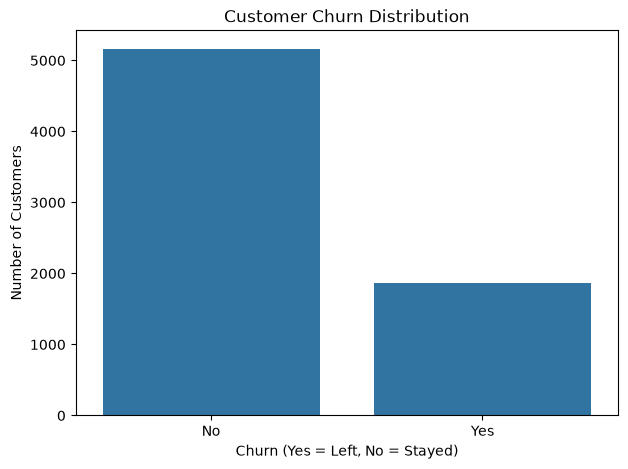


Churn Percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each churn category
print(df["Churn"].value_counts())

# Plot churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Yes = Left, No = Stayed)")
plt.ylabel("Number of Customers")

plt.show()

# Calculate percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
print("\nChurn Percentage:")
print(churn_percentage.round(2))


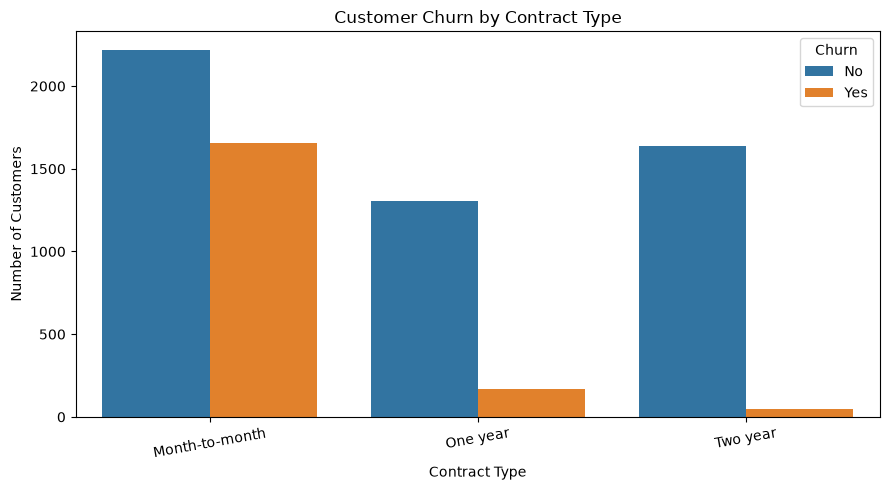

Churn Percentage by Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


In [9]:

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

print("Churn Percentage by Contract Type:")
display(contract_churn.round(2))


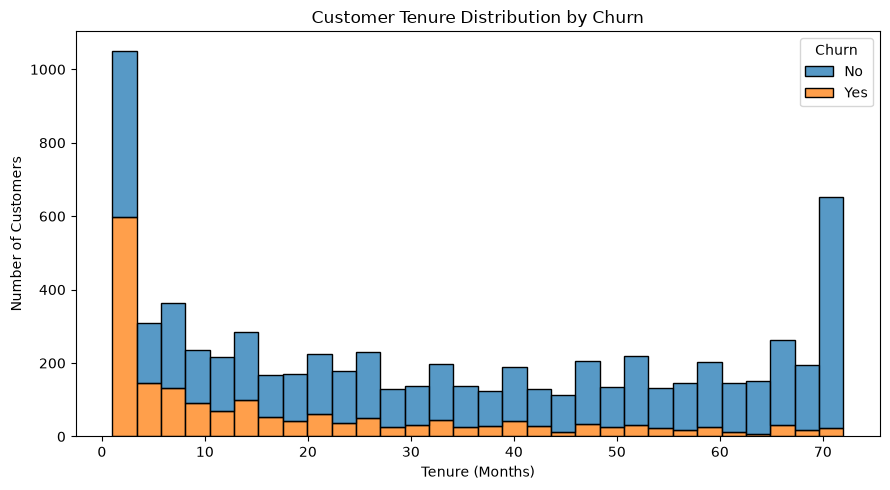

Average Tenure by Churn:


Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64

In [10]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Compare average tenure for churn groups
print("Average Tenure by Churn:")
display(df.groupby("Churn")["tenure"].mean().round(2))


Average Monthly Charges by Churn:


Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64

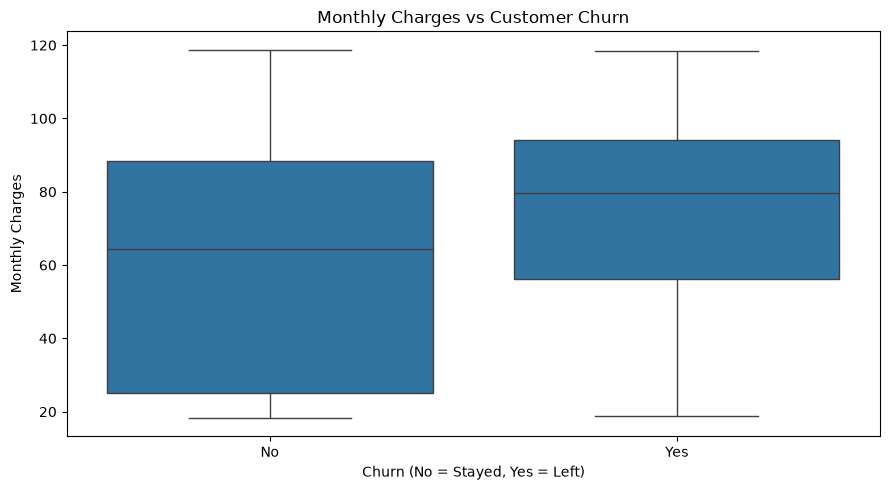

In [11]:

# Compare monthly charges for churn groups
print("Average Monthly Charges by Churn:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# Visualize monthly charges distribution
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


Average Monthly Charges:


Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64

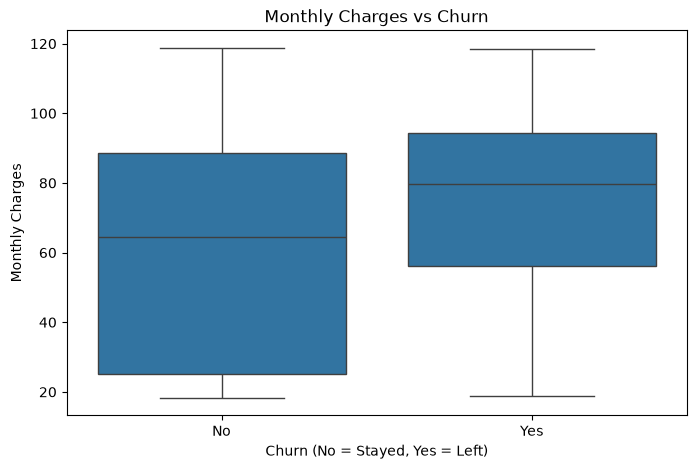

In [12]:

# Compare average monthly charges
print("Average Monthly Charges:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# Compare both groups using a graph
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Monthly Charges")

plt.show()


In [13]:

# Count text and numeric columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()
numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nNumeric Columns:")
print(numeric_cols)

# Check the different values in important categorical columns
for col in ["Contract", "InternetService", "PaymentMethod", "Churn"]:
    print(f"\n{col} values:")
    print(df[col].value_counts())


Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Numeric Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Contract values:
Contract
Month-to-month    3875
Two year          1685
One year          1472
Name: count, dtype: int64

InternetService values:
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

PaymentMethod values:
PaymentMethod
Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: count, dtype: int64

Churn values:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


C:\Users\PITS\AppData\Local\Temp\ipykernel_2900\3126198681.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


In [4]:

# Separate features (X) and target (y)
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [5]:

from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=["str", "object"]).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", len(categorical_cols))
print("Numeric columns:", len(numeric_cols))

# Preview categorical columns
print("\nCategorical columns:")
print(categorical_cols)

# Preview numerical columns
print("\nNumeric columns:")
print(numeric_cols)


Categorical columns: 16
Numeric columns: 3

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

Numeric columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']


In [6]:

from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=["str", "object"]).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", len(categorical_cols))
print("Numeric columns:", len(numeric_cols))

# Preview categorical columns
print("\nCategorical columns:")
print(categorical_cols)

# Preview numerical columns
print("\nNumeric columns:")
print(numeric_cols)


Categorical columns: 16
Numeric columns: 3

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

Numeric columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']
